
# 4장 신경망 학습 — 연습 문제

책 4장 순서(4.1 → 4.5)를 따른다. 해당 절을 읽고 나서 그 Part를 풀자.
`# 여기에 작성`을 채우고 실행(`Shift+Enter`)한 뒤 확인 셀에서 `통과!`가 나오면 성공.
막히면 `ch04_solutions.ipynb` 참고. 커널은 `.venv`.

**표시**
- 🔁 **배치 연습** — 책 범위 안이지만, 행렬·배치를 한꺼번에 다루는 연습으로 더 넣은 문제
- ⭐ **책 범위 밖** — 책 4장 본문에 없는 내용 (5장 미리보기 등). 몰라도 4장 진도에는 문제없음
- ⚠️ **함정** — 자주 틀리는 곳


## 0. 준비
아래 셀을 먼저 실행하자. `check(내 답, 정답, 이름)`이 맞는지 검사해 준다.
노트북을 다시 열었으면 **이 셀부터 다시 실행**하기 (실행 순서 주의!).

`sys.path.append(os.pardir)`는 3장과 같다. 한 칸 위 폴더(`C:\Deeplerning`)에 있는 `dataset`, `common`을 찾게 해 준다.

In [72]:
import sys, os
sys.path.append(os.pardir)   # 한 칸 위 폴더(C:\Deeplerning)도 찾아보게 하기
import numpy as np
import matplotlib.pyplot as plt

# 채점 도우미 (먼저 실행해 두기)
def check(got, want, name='답'):
    if got is None:
        raise AssertionError(f'{name}: 아직 안 채웠어요 (None)')
    if isinstance(want, (tuple, str, bool)):
        ok = got == want
    else:
        ok = np.shape(got) == np.shape(want) and np.allclose(got, want)
    mark = '✅' if ok else '❌'
    print(f'{name} = {got!r}   (정답 {want!r}) {mark}')
    assert ok, f'{name} 이(가) 틀렸어요'

# Part 1. 데이터에서 학습한다! (4.1)
## 1-1. 데이터 주도 학습 (4.1.1)
책은 손글씨 '5'를 알아보는 방법 세 가지를 비교한다.

1. 사람이 생각한 알고리즘 → 결과
2. 사람이 생각한 특징(SIFT, HOG 등) → 기계학습(SVM, KNN 등) → 결과
3. 신경망(딥러닝) → 결과  (이미지를 **있는 그대로** 학습)

특징까지 사람이 설계하지 않고, 데이터에서 **처음부터 끝까지** 기계가 배우는 방식은 몇 번?
- `approach`: 숫자 하나

In [73]:
approach = 3  # 여기에 작성

In [74]:
# 확인
check(approach, 3, 'approach')
print('통과!')

approach = 3   (정답 3) ✅
통과!


## 1-2. 훈련 데이터와 시험 데이터 (4.1.2)
- `eval_data`: 모델의 **범용 능력**(처음 보는 데이터도 잘 맞히는 힘)을 평가할 때 쓰는 데이터. `'훈련'` 또는 `'시험'`
- `overfit_word`: 훈련 데이터에만 지나치게 맞춰져서 다른 데이터는 잘 못 맞히는 상태를 뭐라고 부를까? (한글 4글자)

In [75]:
eval_data = '시험'      # 여기에 작성
overfit_word = '과대적합'   # 여기에 작성

In [76]:
# 확인
check(eval_data, '시험', 'eval_data')
assert overfit_word in ('오버피팅', '과대적합', 'overfitting'), 'overfit_word 다시 생각해 보자'
print('통과!')

eval_data = '시험'   (정답 '시험') ✅
통과!


# Part 2. 손실 함수 (4.2)
## 2-1. 평균 제곱 오차 (4.2.1)
$$E = \frac{1}{2}\sum_k (y_k - t_k)^2$$

- `y`: 신경망의 출력 (소프트맥스 → 확률)
- `t`: 정답 레이블. 정답 자리만 1, 나머지는 0 → **원-핫 인코딩**

먼저 아래 책 예제 데이터를 실행해 두자. (2-3, 2-7에서도 다시 쓴다)

In [77]:
# 책 예제 데이터 (실행만)
t = np.array([0, 0, 1, 0, 0, 0, 0, 0, 0, 0])   # 정답은 '2'
y1 = np.array([0.1, 0.05, 0.6, 0.0, 0.05, 0.1, 0.0, 0.1, 0.0, 0.0])   # '2'일 확률이 가장 높다고 추정
y2 = np.array([0.1, 0.05, 0.1, 0.0, 0.05, 0.1, 0.0, 0.6, 0.0, 0.0])   # '7'일 확률이 가장 높다고 추정

`mean_squared_error(y, t)`를 만들자. (반복문 없이 배열 계산 한 줄로)

In [78]:
def mean_squared_error(y, t):
    sum = np.sum((t-y)*(t-y)) / 2
    return sum

In [79]:
# 확인
check(mean_squared_error(y1, t), 0.0975, 'MSE(y1)')
check(mean_squared_error(y2, t), 0.5975, 'MSE(y2)')
print('통과! 정답에 가까운 y1의 오차가 더 작다.')

MSE(y1) = np.float64(0.09750000000000003)   (정답 0.0975) ✅
MSE(y2) = np.float64(0.5975)   (정답 0.5975) ✅
통과! 정답에 가까운 y1의 오차가 더 작다.


## 2-2. 🔁 원-핫 ↔ 정답 숫자
원-핫 레이블에서 정답 숫자를 꺼내려면 1이 있는 **위치(인덱스)**를 찾으면 된다 → `np.argmax`

- `label`: 위의 `t`에서 정답 숫자 꺼내기
- `labels`: 아래 `T`는 데이터 3개짜리 **배치**다. 각 **행**의 정답 숫자를 한꺼번에 꺼내기 → `[1, 0, 2]`

> 힌트: 행마다(→ 가로 방향으로) 최댓값 위치를 찾으려면 `axis`를 몇으로? 3장 `np.argmax(y_batch, axis=1)`를 떠올리자.

In [80]:
T = np.array([[0, 1, 0],
              [1, 0, 0],
              [0, 0, 1]])

label = np.argmax(t)    # 여기에 작성
labels =  np.argmax(T, axis=1)    # 여기에 작성

print(label) ## 그냥 argmax 를 하면 한 행에 대해서만 찾는 건가?
print(labels)

2
[1 0 2]


In [81]:
# 확인
check(label, 2, 'label')
check(labels, np.array([1, 0, 2]), 'labels')
print('통과!')

label = np.int64(2)   (정답 2) ✅
labels = array([1, 0, 2])   (정답 array([1, 0, 2])) ✅
통과!


## 2-3. 교차 엔트로피 오차 (4.2.2)
$$E = -\sum_k t_k \log y_k$$

### 먼저 예측하기
`np.log(0)`을 계산하면 무엇이 나올까? **실행하지 말고** 적어 보자.
- `predict_log0`: `0`, `1`, `'-inf'`, `'에러'` 중 하나

In [82]:
predict_log0 = '-inf'  # 여기에 작성

In [83]:
# 확인 (이제 실행해서 맞춰 보기)
with np.errstate(divide='ignore'):   # 경고 메시지 숨기기
    print(np.log(0))
assert predict_log0 == '-inf', '다시 생각해 보자'
print('통과! 그래서 y에 아주 작은 값 delta(1e-7)를 더해 -inf를 막는다.')

-inf
통과! 그래서 y에 아주 작은 값 delta(1e-7)를 더해 -inf를 막는다.


이제 `cross_entropy_error(y, t)`를 만들자.
- `delta = 1e-7`을 `y`에 더한 뒤 `np.log`
- 원-핫 `t`를 곱하면 정답 자리 값만 남는다

In [84]:
def cross_entropy_error(y, t):
    delta = 1e-7
    entropy_loss = np.sum(t * np.log(y+delta))
    return -entropy_loss

In [85]:
# 확인
check(cross_entropy_error(y1, t), 0.510825457099338, 'CEE(y1)')
check(cross_entropy_error(y2, t), 2.302584092994546, 'CEE(y2)')
print('통과! 정답 자리 확률 0.6 → 0.51, 0.1 → 2.30')

CEE(y1) = np.float64(0.510825457099338)   (정답 0.510825457099338) ✅
CEE(y2) = np.float64(2.302584092994546)   (정답 2.302584092994546) ✅
통과! 정답 자리 확률 0.6 → 0.51, 0.1 → 2.30


## 2-4. 미니배치 학습 (4.2.3) — MNIST 불러오기
이번엔 `normalize=True, one_hot_label=True`로 불러온다. (정답이 원-핫으로 바뀜)

### 먼저 예측하기
불러온 뒤 `x_train.shape`과 `t_train.shape`은? **튜플로** 적어 보자.

In [86]:
shape_x =   (60000, 784) # 여기에 작성 (예: (3, 4))
shape_t = (60000, 10)   # 여기에 작성

In [87]:
# MNIST 불러오기 (실행만) + 확인
from dataset.mnist import load_mnist

(x_train, t_train), (x_test, t_test) = load_mnist(normalize=True, one_hot_label=True)

print(x_train.shape, t_train.shape)
check(shape_x, (60000, 784), 'shape_x')
check(shape_t, (60000, 10), 'shape_t')
print('통과!')

(60000, 784) (60000, 10)
shape_x = (60000, 784)   (정답 (60000, 784)) ✅
shape_t = (60000, 10)   (정답 (60000, 10)) ✅
통과!


## 2-5. 무작위로 10장 뽑기 (4.2.3)
책 코드처럼
1. `train_size`: 훈련 데이터 개수 (`x_train.shape[0]`)
2. `batch_mask`: `np.random.choice(train_size, batch_size)` — 0 ~ 59999 중 무작위 인덱스 10개
3. `x_batch`, `t_batch`: `batch_mask`로 뽑은 데이터

In [88]:
batch_size = 10

train_size = x_train.shape[0]   # 여기에 작성
batch_mask = np.random.choice(train_size, batch_size)   # trani_size 중에서 무작위 batch_size 개수의 인덱스
x_batch = x_train[batch_mask]      # 여기에 작성
t_batch = t_train[batch_mask]      # 여기에 작성

In [89]:
# 확인
print(batch_mask)
check(train_size, 60000, 'train_size')
check(x_batch.shape, (10, 784), 'x_batch.shape')
check(t_batch.shape, (10, 10), 't_batch.shape')
assert np.array_equal(t_batch, t_train[batch_mask]), 't_batch는 같은 batch_mask로 뽑아야 짝이 맞는다'
print('통과!')

[43194 42844 24276 17638   178 14376 47974 20957  8237 59922]
train_size = 60000   (정답 60000) ✅
x_batch.shape = (10, 784)   (정답 (10, 784)) ✅
t_batch.shape = (10, 10)   (정답 (10, 10)) ✅
통과!


## 2-6. 🔁 인덱스 배열로 여러 행 뽑기 — 예측하기
**실행하지 말고** 모양을 튜플로 적어 보자.
- `predict_a`: `x_train[0].shape`
- `predict_b`: `x_train[[0]].shape`  ← 대괄호가 두 겹!
- `predict_c`: `x_train[[0, 5, 9]].shape`

그다음 `picked_labels`: 0번, 5번, 9번 훈련 데이터의 정답 숫자 3개를 **한 줄로** 꺼내자. (2-2의 `argmax` 활용)

In [90]:
predict_a = (784, )   # 여기에 작성
predict_b = (1, 784)   # 여기에 작성
predict_c = (3, 784)   # 여기에 작성

picked_labels = np.argmax(t_train[[0, 5, 9]], axis= 1)   # 여기에 작성

In [91]:
# 확인 (이제 실행해서 맞춰 보기)
print(x_train[0].shape, x_train[[0]].shape, x_train[[0, 5, 9]].shape)
check(predict_a, (784,), 'predict_a')
check(predict_b, (1, 784), 'predict_b')
check(predict_c, (3, 784), 'predict_c')
check(picked_labels, np.array([5, 2, 4]), 'picked_labels')
print('통과!')

(784,) (1, 784) (3, 784)
predict_a = (784,)   (정답 (784,)) ✅
predict_b = (1, 784)   (정답 (1, 784)) ✅
predict_c = (3, 784)   (정답 (3, 784)) ✅
picked_labels = array([5, 2, 4])   (정답 array([5, 2, 4])) ✅
통과!


## 2-7. (배치용) 교차 엔트로피 오차 — 원-핫 버전 (4.2.4)
배치로 넣으면 데이터 N개의 손실을 **모두 더하고 N으로 나눠** 평균을 낸다.

$$E = -\frac{1}{N}\sum_n \sum_k t_{nk} \log y_{nk}$$

### 먼저 예측하기
`y1`은 길이 10짜리 1차원 배열이다. `y1.reshape(1, y1.size).shape`은?

In [92]:
predict_reshape = (1, 10)   # 여기에 작성

In [93]:

# 확인
print(y1.reshape(1, y1.size).shape)
check(predict_reshape, (1, 10), 'predict_reshape')
print('통과!')

(1, 10)
predict_reshape = (1, 10)   (정답 (1, 10)) ✅
통과!


책 코드처럼 `cross_entropy_error_batch(y, t)`를 만들자.
1. `y.ndim == 1`이면 (데이터 1개) `t`, `y`를 둘 다 `reshape(1, 크기)`로 바꾼다 → 이제 항상 2차원
2. `batch_size = y.shape[0]`
3. `-np.sum(t * np.log(y + 1e-7)) / batch_size`

> 1번 덕분에 데이터 1개든 100개든 **같은 코드**로 계산된다.

In [94]:
def cross_entropy_error_batch(y, t):
    if y.ndim == 1:
        t = t.reshape(1, t.size)
        y = y.reshape(1, y.size)

    batch_size = y.shape[0] #이게 무슨 소리지? y 는 들어오는 값인데 애초에 사용자가 batch size 에 따라서 선별한 값을 넣는다고 가정하고 있는건가?
    sum = -np.sum(t * np.log(y + 1e-7)) / batch_size # batch 사이즈로 나누는 이유를 각 행렬을 상황을 가정해서 보여줄 수 있나?

    return sum


In [95]:
# 확인
Y = np.array([y1, y2])   # (2, 10) 배치
T2 = np.array([t, t])    # (2, 10) 정답도 2개
print(Y.shape, T2.shape)
check(cross_entropy_error_batch(y1, t), 0.510825457099338, 'CEE_batch(y1)')
check(cross_entropy_error_batch(Y, T2), 1.406704775046942, 'CEE_batch(Y)')   # (0.51 + 2.30) / 2
print('통과!')

(2, 10) (2, 10)
CEE_batch(y1) = np.float64(0.510825457099338)   (정답 0.510825457099338) ✅
CEE_batch(Y) = np.float64(1.406704775046942)   (정답 1.406704775046942) ✅
통과!


## 2-8. (배치용) 교차 엔트로피 오차 — 정답 레이블 버전 (4.2.4)
정답이 원-핫이 아니라 `[2, 7, 0, ...]`처럼 **숫자**로 오면, 정답 자리 확률만 바로 뽑으면 된다.

### 🔁 먼저 예측하기
**실행하지 말고** `Yp[np.arange(3), tp]`의 값을 리스트로 적어 보자.

```python
Yp = np.array([[0.1, 0.7, 0.2],
               [0.6, 0.3, 0.1],
               [0.2, 0.2, 0.6]])
tp = np.array([1, 0, 2])
```
> 힌트: `np.arange(3)` = `[0, 1, 2]`(행 번호), `tp` = 열 번호. 둘을 **짝지어** `(0, 1)`, `(1, 0)`, `(2, 2)` 자리를 꺼낸다.

In [96]:
predict_pick = [0.7, 0.6, 0.6]   # 여기에 작성 (예: [0.1, 0.2, 0.3])

## 이 방식 중요해 보임. 까먹기 쉬운 내용인 거 같은데 중요한 내용인 거 같아서 노트에 정리할 필요가 있어보임. 

In [97]:
# 확인 (이제 실행해서 맞춰 보기)
Yp = np.array([[0.1, 0.7, 0.2],
               [0.6, 0.3, 0.1],
               [0.2, 0.2, 0.6]])
tp = np.array([1, 0, 2])
print(Yp[np.arange(3), tp])
check(predict_pick, [0.7, 0.6, 0.6], 'predict_pick')
print('통과!')

[0.7 0.6 0.6]
predict_pick = [0.7, 0.6, 0.6]   (정답 [0.7, 0.6, 0.6]) ✅
통과!


이제 `cross_entropy_error_label(y, t)`를 만들자. 2-7과 같은 틀에서 마지막 줄만 바뀐다.

`-np.sum(np.log(y[np.arange(batch_size), t] + 1e-7)) / batch_size`

In [98]:
def cross_entropy_error_label(y, t):
    if y.ndim == 1: 
        y = y.reshape(1, y.size)
        t = t.reshape(1, t.size)

    #t는 one-hot encoding 되어 잇지 않음. 따라서 행 별로 해당 인덱스에 있는 값을 선택하는 것드로 구해야 됨. 
    #이렇게 연산할 수 있는 이유는 cross entropy 를 이용하기 떄문에 정답이 아닌 곳은 0으로 고려할 필요가 없어서 1인 영역만 선택하는 형식으로 구현할 수 있기 때문임. 

    batch_size = y.shape[0]
    result = y[np.arange(batch_size), t]
    loss = - np.sum(np.log(result + 1e-7))/batch_size

    return loss

In [99]:
# 확인: 원-핫 버전(2-7)과 같은 값이 나와야 한다
t_label = np.array([2, 2])   # Y의 두 데이터 모두 정답은 '2'
check(cross_entropy_error_label(Y, t_label), 1.406704775046942, 'CEE_label(Y)')
check(cross_entropy_error_label(Y, t_label), cross_entropy_error_batch(Y, T2), '원-핫 버전과 비교')
print('통과!')

CEE_label(Y) = np.float64(1.406704775046942)   (정답 1.406704775046942) ✅
원-핫 버전과 비교 = np.float64(1.406704775046942)   (정답 np.float64(1.406704775046942)) ✅
통과!


## 2-9. 왜 손실 함수를 설정하는가? (4.2.5)
시험 100장 중 32장을 맞혀서 정확도가 0.32인 신경망이 있다.
가중치를 **아주 조금** 바꾸면 정확도는 0.32 그대로이거나, 갑자기 0.33으로 '뚝' 바뀐다.

- `acc_grad`: 그래서 정확도를 가중치로 미분하면 대부분의 곳에서 값이 몇일까? (숫자)
- `activation`: 같은 이유로, 활성화 함수로 계단 함수 대신 무엇을 쓸까? (한글 또는 영어)

In [100]:
acc_grad = 0     # 여기에 작성
activation = 'sigmoid'   # 여기에 작성

In [101]:
# 확인
check(acc_grad, 0, 'acc_grad')
assert activation in ('시그모이드', 'sigmoid', 'Sigmoid', '시그모이드 함수'), 'activation 다시 생각해 보자'
print('통과! 그래서 정확도 대신 매끄럽게 변하는 손실 함수를 지표로 쓴다.')

acc_grad = 0   (정답 0) ✅
통과! 그래서 정확도 대신 매끄럽게 변하는 손실 함수를 지표로 쓴다.


# Part 3. 수치 미분 (4.3)
## 3-1. 나쁜 구현 예 — 반올림 오차 (4.3.1)
책은 `h = 1e-50`처럼 너무 작은 값을 쓰면 안 된다고 한다.

### 먼저 예측하기
`np.float32(1e-50)`은 무엇으로 표시될까? (숫자)

In [102]:
predict_f32 = 0.0   # 여기에 작성

In [103]:
# 확인 (이제 실행해서 맞춰 보기)
print(np.float32(1e-50))
check(predict_f32, 0.0, 'predict_f32')
print('통과! 그래서 h는 1e-4 정도를 쓴다.')

0.0
predict_f32 = 0.0   (정답 0.0) ✅
통과! 그래서 h는 1e-4 정도를 쓴다.


## 3-2. 수치 미분 — 중심 차분 (4.3.1)
책의 두 가지 개선을 넣어 `numerical_diff(f, x)`를 만들자.
1. `h = 1e-4`
2. **중심 차분**: $\dfrac{f(x+h) - f(x-h)}{2h}$

In [104]:
def numerical_diff(f, x):
    h = 1e-4
    return ((f(x + h) - f(x - h)) / (2*h))

In [105]:
# 확인: x**2 의 x=3에서 기울기는 2*3 = 6
check(numerical_diff(lambda x: x ** 2, 3.0), 6.0, 'numerical_diff(x**2, 3)')
print('통과!')

numerical_diff(x**2, 3) = 6.000000000012662   (정답 6.0) ✅
통과!


## 3-3. 수치 미분의 예 (4.3.2)
$$y = 0.01x^2 + 0.1x$$
- `function_1(x)`를 만들자
- `d5`, `d10`: `x = 5`, `x = 10`에서의 미분값 (`numerical_diff` 사용)

> 해석적으로 풀면 $0.02x + 0.1$ → 0.2, 0.3이 나와야 한다.

In [106]:
def function_1(x):
    return 0.01*x**2 + 0.1*x

d5 = numerical_diff(function_1, 5)
d10 = numerical_diff(function_1, 10)

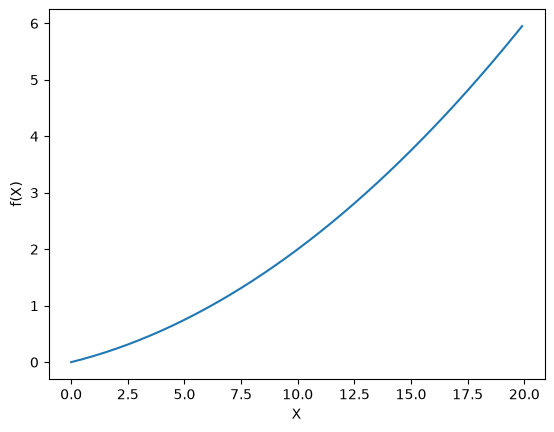

In [107]:
import numpy as np
import matplotlib.pyplot as plt

x = np.arange(0.0, 20.0, 0.1)
y = function_1(x)

plt.xlabel('X')
plt.ylabel('f(X)')

plt.plot(x, y)

plt.show()

In [108]:
# 확인
check(d5, 0.2, 'd5')
check(d10, 0.3, 'd10')
print('통과! (아주 작은 오차는 수치 미분이라 생기는 것)')

d5 = 0.1999999999990898   (정답 0.2) ✅
d10 = 0.2999999999986347   (정답 0.3) ✅
통과! (아주 작은 오차는 수치 미분이라 생기는 것)


In [109]:
df_val = numerical_diff(function_1, 5)

print(df_val)

0.1999999999990898


### 🔁 그래프 그리기 (실행만)
`function_1`은 숫자 하나에도, **배열 전체에도** 그대로 쓸 수 있다. `x`에 200개짜리 배열을 넣으면 `y`도 200개가 한꺼번에 계산된다.

(200,) (200,)


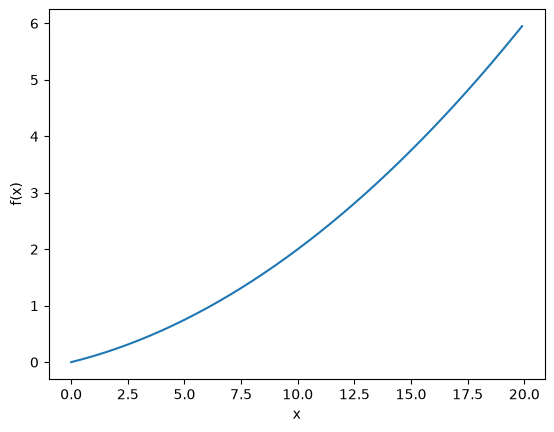

In [110]:
x = np.arange(0.0, 20.0, 0.1)   # 0 ~ 19.9, 0.1 간격 → 200개
y = function_1(x)               # 배열을 한꺼번에 계산
print(x.shape, y.shape)

plt.xlabel('x')
plt.ylabel('f(x)')
plt.plot(x, y)
plt.show()

## 3-4. 접선 그리기 (책 코드 `gradient_1d.py`)
책 그림 4-7처럼 `x = 5`에서의 **접선**을 그려 보자. `tangent_line(f, x)`는 접선을 나타내는 **함수**를 돌려준다.
1. `d = numerical_diff(f, x)` — 기울기
2. `y = f(x) - d * x` — 절편 (접선이 점 $(x, f(x))$를 지나니까)
3. `return lambda t: d * t + y`

In [111]:
def tangent_line(f, x):
    diff_f =  numerical_diff(f, x)

    return lambda t: diff_f*(t-x) + f(x)

    
    

tf(0) = -0.24999999999544897   (정답 -0.25) ✅


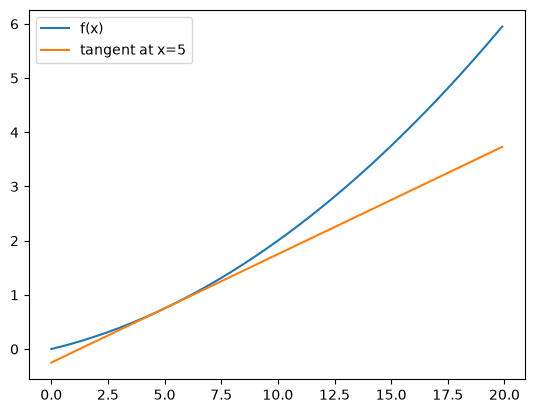

통과!


In [112]:
# 확인 + 그래프
tf = tangent_line(function_1, 5)
check(tf(0), -0.25, 'tf(0)')   # f(5) = 0.75, 기울기 0.2 → 0.75 - 0.2*5 = -0.25

plt.plot(x, function_1(x), label='f(x)')
plt.plot(x, tf(x), label='tangent at x=5')   # tf에도 배열을 한꺼번에 넣을 수 있다
plt.legend()
plt.show()
print('통과!')

## 3-5. 편미분 (4.3.3)
$$f(x_0, x_1) = x_0^2 + x_1^2$$
- `function_2(x)`: `x`는 원소 2개짜리 넘파이 배열 (`x[0]`, `x[1]`)
- `d_x0`: $x_0=3, x_1=4$일 때 $x_0$에 대한 편미분 → $x_1$을 4로 **고정**한 함수 `function_tmp1`을 만들어 `numerical_diff`
- `d_x1`: 같은 점에서 $x_1$에 대한 편미분 → `function_tmp2`

In [113]:
def function_2(x):
    return np.sum(x**2)


def function_tmp1(x0):
    return x0 * x0 + 4.0 ** 2.0    # x1 = 4로 고정 (미분 X)

def function_tmp2(x1):
    return 3.0 ** 2.0 + x1 * x1    # x0 = 3으로 고정

d_x0 = numerical_diff(function_tmp1, 3.0)   # 여기에 작성
d_x1 = numerical_diff(function_tmp2, 4.0)   # 여기에 작성

In [114]:
# 확인
check(function_2(np.array([3.0, 4.0])), 25.0, 'function_2([3, 4])')
check(d_x0, 6.0, 'd_x0')
check(d_x1, 8.0, 'd_x1')
print('통과!')

function_2([3, 4]) = np.float64(25.0)   (정답 25.0) ✅
d_x0 = 6.00000000000378   (정답 6.0) ✅
d_x1 = 7.999999999999119   (정답 8.0) ✅
통과!


# Part 4. 기울기 (4.4)
## 4-1. 기울기 한꺼번에 구하기 (4.4)
편미분을 하나씩 따로 하지 말고, 모든 변수의 편미분을 **벡터 하나로** 구하자 → 기울기(gradient)

`numerical_gradient(f, x)` 만드는 방법 (책 코드)
1. `grad = np.zeros_like(x)` — `x`와 모양이 같은 0 배열
2. `for idx in range(x.size):`
   - `tmp_val = x[idx]` (원래 값 저장)
   - `x[idx] = tmp_val + h` → `fxh1 = f(x)`
   - `x[idx] = tmp_val - h` → `fxh2 = f(x)`
   - `grad[idx] = (fxh1 - fxh2) / (2*h)`
   - `x[idx] = tmp_val` (**값 복원!**)

In [115]:
def numerical_gradient(f, x):
    h = 1e-4
    grad = np.zeros_like(x)

    # 여기에 작성
    # 각 변수에 대해서 하나씩 돌아가면서 미분 값을 구한다. 
    for i in range(x.size):
        tmp_val = x[i]
        x[i] = tmp_val + h   # 이 위치에 있는 값만 갱신해주기
        fpx = f(x) #numpy 배열에서 다른 값들을 전부 복제하는 게 번거롭기 때문에 그냥 원본 데이터를 변경해줌. -> 그러니 위해 원본 데이터는 남겨둠. 


        x[i] = tmp_val -h
        fmx = f(x)

        grad[i] = (fpx-fmx)/(2*h)
        x[i] = tmp_val
        
    return grad

In [116]:
# 확인 (책의 세 점)
check(numerical_gradient(function_2, np.array([3.0, 4.0])), np.array([6.0, 8.0]), '(3, 4)')
check(numerical_gradient(function_2, np.array([0.0, 2.0])), np.array([0.0, 4.0]), '(0, 2)')
check(numerical_gradient(function_2, np.array([3.0, 0.0])), np.array([6.0, 0.0]), '(3, 0)')
print('통과!')

(3, 4) = array([6., 8.])   (정답 array([6., 8.])) ✅
(0, 2) = array([0., 4.])   (정답 array([0., 4.])) ✅
(3, 0) = array([6., 0.])   (정답 array([6., 0.])) ✅
통과!


## 4-2. ⚠️ 함정 — 정수 배열을 넣으면?
책은 항상 `3.0`처럼 **소수점**을 붙여서 넣는다. 아래처럼 정수 배열을 넣으면 어떻게 될까? (실행만)

In [117]:
print(numerical_gradient(function_2, np.array([3, 4])))   # 정답은 [6, 8]인데...

[25000 35000]


정수 배열에 `3 + 0.0001`을 넣으면 소수점이 **잘려서** 그냥 `3`이 된다. 그래서 엉뚱한 값이 나온다.
- `x_ok`: 같은 점 $(3, 4)$를 **올바르게** 넣는 배열을 만들자

In [118]:
x_ok = np.array([3.0, 4.0])   # 여기에 작성

In [119]:
# 확인
print(x_ok.dtype)
assert x_ok.dtype.kind == 'f', 'float 배열이어야 한다'
check(numerical_gradient(function_2, x_ok), np.array([6.0, 8.0]), 'grad(x_ok)')
print('통과!')

float64
grad(x_ok) = array([6., 8.])   (정답 array([6., 8.])) ✅
통과!


## 4-3. 🔁 여러 점의 기울기를 한꺼번에 (책 코드 `gradient_2d.py`)
책 그림 4-9는 점 수백 개의 기울기를 그린 것이다. 책의 `gradient_2d.py`는 **점을 행으로 쌓은 2차원 배열**을 받아서, 행마다 4-1의 함수를 부른다.

### 먼저 예측하기
점 3개를 쌓은 `P = np.array([[3.0, 4.0], [0.0, 2.0], [3.0, 0.0]])`의 기울기 배열 모양은? (튜플)

In [120]:
predict_grad_shape = (3, 2)  # 여기에 작성

`numerical_gradient_2d(f, X)`를 만들자.
- `X.ndim == 1`이면 4-1의 `numerical_gradient(f, X)`를 그대로 돌려준다
- 아니면 `grad = np.zeros_like(X)`를 만들고, `for idx, x in enumerate(X):`로 **행마다** `grad[idx] = numerical_gradient(f, x)`

In [121]:
def numerical_gradient_2d(f, X):
    if X.ndim == 1:
        return numerical_gradient(f, X)

    grad = np.zeros_like(X)  
    for idx, x in enumerate(X):
        grad[idx] = numerical_gradient(f, x)

    return grad

In [122]:
# 확인
P = np.array([[3.0, 4.0],
              [0.0, 2.0],
              [3.0, 0.0]])
G = numerical_gradient_2d(function_2, P)
print(G)
check(G.shape, predict_grad_shape, 'G.shape')
check(G, np.array([[6.0, 8.0], [0.0, 4.0], [6.0, 0.0]]), 'G')
print('통과!')

[[6. 8.]
 [0. 4.]
 [6. 0.]]
G.shape = (3, 2)   (정답 (3, 2)) ✅
G = array([[6., 8.],
       [0., 4.],
       [6., 0.]])   (정답 array([[6., 8.],
       [0., 4.],
       [6., 0.]])) ✅
통과!


### 🔁 책 그림 4-9 그리기 — 모양 예측
아래 코드에서 `x0`는 원소 18개, 격자는 18 × 18 = 324개 점이다.
**실행하지 말고** 모양을 튜플로 적어 보자.
- `predict_xy`: `np.array([X, Y]).shape`   (`X`, `Y`는 `flatten`해서 각각 길이 324)
- `predict_xyT`: `np.array([X, Y]).T.shape`

In [125]:
predict_xy = (2, 324)    # 여기에 작성
predict_xyT = (324, 2)   # 여기에 작성

In [ ]:
# 확인
check(predict_xy, (2, 324), 'predict_xy')
check(predict_xyT, (324, 2), 'predict_xyT')
print('통과!')

### ✍️ 책 그림 4-9 직접 그리기
아래 순서대로 **처음부터** 코드를 짜 보자. (막히면 `ch04_solutions.ipynb`의 같은 자리를 보기)

1. 눈금: `x0`, `x1` — `np.arange(-2, 2.5, 0.25)` (각 18개)
2. 격자: `np.meshgrid(x0, x1)` → `X`, `Y` (각 `(18, 18)`)
3. 펴기: `flatten()` → 각 길이 324
4. 기울기: `numerical_gradient_2d(function_2, 점 324개를 행으로 쌓은 배열)` → 그리기 좋게 다시 `.T` 해서 `(2, 324)`로
5. 화살표: `plt.quiver(X, Y, U, V)`

| `plt.quiver` 인자 | 뜻 |
|---|---|
| `X`, `Y` | 화살표를 그릴 **점의 좌표** |
| `U`, `V` | 각 화살표의 **가로·세로 길이(방향)** — 함수가 **작아지는** 방향이니까 기울기에 마이너스 |

꾸미기(선택): `plt.xlim([-2, 2])`, `plt.ylim([-2, 2])`, `plt.xlabel('x0')`, `plt.ylabel('x1')`, `plt.grid()`, `plt.show()`

완성되면 화살표가 모두 가운데 (0, 0)을 가리켜야 한다.

In [ ]:
# 여기에 작성 (그림 4-9 직접 그리기)


## 4-4. 경사 하강법 (4.4.1)
$$x \leftarrow x - \eta \frac{\partial f}{\partial x}$$
($\eta$ = 학습률 `lr`)

`gradient_descent(f, init_x, lr=0.01, step_num=100)` (책 코드)
1. `x = init_x`
2. `step_num`번 반복: `grad = numerical_gradient(f, x)` → `x -= lr * grad`
3. `return x`

In [ ]:
def gradient_descent(f, init_x, lr=0.01, step_num=100):
    pass   # 여기에 작성

In [ ]:
# 확인 (책 예제): (-3, 4)에서 시작 → 최솟값 (0, 0) 근처로
result = gradient_descent(function_2, init_x=np.array([-3.0, 4.0]), lr=0.1, step_num=100)
print(result)   # 약 [-6.1e-10, 8.1e-10] → 거의 0
check(result, np.array([0.0, 0.0]), 'result')
print('통과!')

## 4-5. 학습률이 너무 크거나 작으면? (4.4.1)
### 먼저 예측하기
`(-3, 4)`에서 시작해서 100번 이동할 때, 결과는 어떻게 될까?
- `predict_big`: `lr=10.0`일 때 → `'발산'` 또는 `'거의 그대로'`
- `predict_small`: `lr=1e-10`일 때 → `'발산'` 또는 `'거의 그대로'`

In [ ]:
predict_big = None     # 여기에 작성
predict_small = None   # 여기에 작성

In [ ]:
# 확인 (이제 실행해서 맞춰 보기)
big = gradient_descent(function_2, init_x=np.array([-3.0, 4.0]), lr=10.0, step_num=100)
small = gradient_descent(function_2, init_x=np.array([-3.0, 4.0]), lr=1e-10, step_num=100)
print('lr=10   :', big)
print('lr=1e-10:', small)
check(predict_big, '발산', 'predict_big')
check(predict_small, '거의 그대로', 'predict_small')
print('통과! 학습률 같은 값을 하이퍼파라미터라고 하고, 사람이 직접 정한다.')

## 4-6. ⚠️ 함정 — `init_x`도 바뀐다 (복사 vs 같은 배열)
1장에서 헷갈렸던 '뷰(같은 배열) vs 복사' 문제가 여기서도 나온다.

```python
init_x = np.array([-3.0, 4.0])
result = gradient_descent(function_2, init_x, lr=0.1)
print(init_x)
```
### 먼저 예측하기
- `predict_same`: `result is init_x`는 `True`일까 `False`일까? (`is` = 완전히 같은 배열인가)

> 힌트: 함수 안의 `x = init_x`는 복사일까, 이름만 하나 더 붙인 걸까? 그리고 `x -= ...`는 배열을 **그 자리에서** 바꾼다.

In [ ]:
predict_same = None   # 여기에 작성 (True 또는 False)

In [ ]:
# 확인 (이제 실행해서 맞춰 보기)
init_x = np.array([-3.0, 4.0])
result = gradient_descent(function_2, init_x, lr=0.1)
print('init_x:', init_x)
print('result is init_x:', result is init_x)
check(predict_same, True, 'predict_same')
print('통과! 원래 값을 지키고 싶으면 함수 안에서 x = init_x.copy() 로 쓰면 된다. (책 코드는 매번 새 배열을 넣어서 문제없다)')

### 책 그림 4-10 그리기 (책 코드 `gradient_method.py`, 실행만)
이동한 자리를 `x_history`에 모아서 점으로 찍어 본다. 여기선 `init_x.copy()`로 원래 값을 지킨다.

In [ ]:
x = np.array([-3.0, 4.0])
x_history = []
for i in range(20):
    x_history.append(x.copy())   # .copy()가 없으면 모두 같은 배열(마지막 값)이 된다!
    x -= 0.1 * numerical_gradient(function_2, x)

x_history = np.array(x_history)   # (20, 2) — 행 하나가 한 번의 위치
print(x_history.shape)

plt.plot([-5, 5], [0, 0], '--b')
plt.plot([0, 0], [-5, 5], '--b')
plt.plot(x_history[:, 0], x_history[:, 1], 'o')   # 0열 = x0 좌표들, 1열 = x1 좌표들
plt.xlim(-3.5, 3.5); plt.ylim(-4.5, 4.5)
plt.xlabel('X0'); plt.ylabel('X1')
plt.show()

## 4-7. 신경망에서의 기울기 (4.4.2) — 책 `common` 파일 쓰기
이제부터는 책 저장소에서 복사해 둔 `common` 폴더의 함수를 쓴다.
- `common.functions`: `sigmoid`, `softmax`, `cross_entropy_error`
  - 이 `softmax`는 **배치(2차원)도** 행마다 계산해 준다
  - 이 `cross_entropy_error`는 정답이 **원-핫이든 숫자든** 둘 다 받는다 (원-핫이면 `argmax`로 숫자로 바꾼 뒤 2-8 방식)
- `common.gradient`: `numerical_gradient` — 4-1과 같은 일을 하는데, `W`처럼 **2차원 배열도** 받는다

> 아래 셀을 실행하면 2-3에서 만든 `cross_entropy_error`, 4-1에서 만든 `numerical_gradient`가 책 버전으로 **덮어써진다**.

In [ ]:
from common.functions import sigmoid, softmax, cross_entropy_error
from common.gradient import numerical_gradient

### 🔁 먼저 예측하기 — 모양
`W`는 (2, 3)이다. **실행하지 말고** 튜플로 적어 보자.
- `predict_z`: `x = np.array([0.6, 0.9])`일 때 `np.dot(x, W).shape`
- `predict_Z`: 입력 4개를 쌓은 `X4`가 (4, 2)일 때 `np.dot(X4, W).shape`
- `predict_dW`: 손실을 `W`로 미분한 기울기 `dW`의 모양

In [ ]:
predict_z = None    # 여기에 작성
predict_Z = None    # 여기에 작성
predict_dW = None   # 여기에 작성

In [ ]:
# 확인
Wtmp = np.zeros((2, 3))
print(np.dot(np.array([0.6, 0.9]), Wtmp).shape, np.dot(np.zeros((4, 2)), Wtmp).shape)
check(predict_z, (3,), 'predict_z')
check(predict_Z, (4, 3), 'predict_Z')
check(predict_dW, (2, 3), 'predict_dW')
print('통과!')

### simpleNet 클래스 (책 코드 `gradient_simplenet.py`)
- `__init__`: `self.W = np.random.randn(2, 3)` — 정규분포로 초기화
- `predict(x)`: `np.dot(x, self.W)`
- `loss(x, t)`: `predict` → `softmax` → `cross_entropy_error`

In [ ]:
class simpleNet:
    def __init__(self):
        pass   # 여기에 작성

    def predict(self, x):
        pass   # 여기에 작성

    def loss(self, x, t):
        pass   # 여기에 작성

In [ ]:
# 확인: 책과 같은 숫자가 나오도록 W를 책 값으로 바꿔 넣는다
net = simpleNet()
net.W = np.array([[0.47355232, 0.9977393, 0.84668094],
                  [0.85557411, 0.03563661, 0.69422093]])

x = np.array([0.6, 0.9])
p = net.predict(x)
print(p)
check(p, np.array([1.05414809, 0.63071653, 1.1328074]), 'p')
check(np.argmax(p), 2, 'np.argmax(p)')   # 최댓값 인덱스

t = np.array([0, 0, 1])   # 정답 레이블
check(net.loss(x, t), 0.92806853663411326, 'loss')
print('통과!')

## 4-8. 가중치의 기울기 `dW` (4.4.2)
- `f`: `W`를 받아서 손실을 돌려주는 함수 → `lambda w: net.loss(x, t)`
- `dW`: `numerical_gradient(f, net.W)`

> `w`를 받기만 하고 안 쓰는 게 이상해 보이는데, `numerical_gradient`가 `net.W`의 값을 **직접** 바꿔 가며 `f`를 부르기 때문에 이렇게 해도 된다. (`f(x)` 꼴로 부를 수 있게 모양만 맞춘 것)

In [ ]:
f = None    # 여기에 작성
dW = None   # 여기에 작성

In [ ]:
# 확인
print(dW)
check(dW, np.array([[0.21924763, 0.14356247, -0.36281009],
                    [0.32887144, 0.2153437, -0.54421514]]), 'dW')
print('통과!')

### 생각해 보기
`dW[0, 0]`(= $\frac{\partial L}{\partial w_{11}}$)은 약 0.2로 **양수**다.
- `direction_w11`: 손실을 줄이려면 $w_{11}$을 어느 쪽으로 바꿔야 할까? `'+'` 또는 `'-'`
- `biggest`: 손실에 가장 크게 영향을 주는 원소는 `dW`에서 절댓값이 가장 큰 곳이다. 그 위치를 `(행, 열)` 튜플로 (0부터 셈)

In [ ]:
direction_w11 = None   # 여기에 작성
biggest = None         # 여기에 작성

In [ ]:
# 확인
check(direction_w11, '-', 'direction_w11')
check(biggest, (1, 2), 'biggest')
print('통과!')

## 4-9. 🔁 simpleNet에 배치 넣기
`simpleNet`은 입력을 **여러 개 쌓아서** 넣어도 그대로 동작한다. (`np.dot`, `softmax`, `cross_entropy_error`가 모두 배치를 받으니까)

- `P3`: 아래 `X3`(입력 3개)를 `net.predict`에 한 번에 넣은 결과
- `L3`: 정답 숫자 `t3 = [2, 0, 1]`로 구한 배치 손실 (`net.loss` 한 번)

> `X3`의 2번째 행 `[1, 0]`을 넣으면 `W`의 몇 번째 행이 그대로 나올까? 확인 셀에서 보자.

In [ ]:
X3 = np.array([[0.6, 0.9],
               [1.0, 0.0],
               [0.0, 1.0]])
t3 = np.array([2, 0, 1])

P3 = None   # 여기에 작성
L3 = None   # 여기에 작성

In [ ]:
# 확인
print(P3)
check(P3.shape, (3, 3), 'P3.shape')
check(P3[0], p, 'P3[0] (4-7의 p와 같다)')
check(P3[1], net.W[0], 'P3[1] ([1, 0] → W의 0번 행)')
check(L3, 1.3327377484113454, 'L3')
print('통과!')

# Part 5. 학습 알고리즘 구현하기 (4.5)
신경망 학습은 아래 4단계를 반복한다.
1. **미니배치**: 훈련 데이터 중 일부를 무작위로 뽑는다
2. **기울기 산출**: 미니배치의 손실을 줄이는 방향(기울기)을 구한다
3. **매개변수 갱신**: 기울기 방향으로 아주 조금 이동
4. **반복**: 1~3

- `sgd_name`: 무작위로 뽑은 데이터로 경사 하강법을 하는 이 방법의 영어 약자 3글자는?

In [ ]:
sgd_name = None   # 여기에 작성

In [ ]:
# 확인
check(sgd_name, 'SGD', 'sgd_name')
print('통과!')

## 5-1. 🔁 TwoLayerNet 모양 예측 (4.5.1)
`TwoLayerNet(input_size=784, hidden_size=100, output_size=10)`을 만든다.
**실행하지 말고** 모양을 튜플로 적어 보자.
- `shape_W1`, `shape_b1`, `shape_W2`, `shape_b2`
- 이미지 3장을 쌓은 `x`(3, 784)를 넣을 때: `shape_a1` (첫 번째 층 `np.dot(x, W1) + b1`), `shape_y` (출력)

> ⚠️ 원소가 하나인 튜플은 `(100,)`처럼 **쉼표**가 필요하다. `(100)`은 그냥 숫자 100이다.

In [ ]:
shape_W1 = None   # 여기에 작성
shape_b1 = None   # 여기에 작성
shape_W2 = None   # 여기에 작성
shape_b2 = None   # 여기에 작성
shape_a1 = None   # 여기에 작성
shape_y = None    # 여기에 작성

In [ ]:
# 확인
check(shape_W1, (784, 100), 'shape_W1')
check(shape_b1, (100,), 'shape_b1')
check(shape_W2, (100, 10), 'shape_W2')
check(shape_b2, (10,), 'shape_b2')
check(shape_a1, (3, 100), 'shape_a1')
check(shape_y, (3, 10), 'shape_y')
print('통과!')

## 5-2. TwoLayerNet 클래스 (4.5.1, 책 코드 `two_layer_net.py`)
| 메서드 | 할 일 |
|---|---|
| `__init__` | `self.params` 딕셔너리에 `'W1'`, `'b1'`, `'W2'`, `'b2'`를 **이 순서로** 넣는다. W는 `weight_init_std * np.random.randn(...)`, b는 `np.zeros(...)` |
| `predict(x)` | `a1 = x·W1 + b1` → `z1 = sigmoid(a1)` → `a2 = z1·W2 + b2` → `y = softmax(a2)` |
| `loss(x, t)` | `predict` 후 `cross_entropy_error` |
| `accuracy(x, t)` | 예측과 정답을 각각 `np.argmax(..., axis=1)` → 같은 개수 / 데이터 수 |
| `numerical_gradient(x, t)` | `loss_W = lambda W: self.loss(x, t)` → `grads` 딕셔너리에 4개 키의 기울기 |

> 메서드 안의 `numerical_gradient(loss_W, ...)`는 메서드 자신이 아니라 위에서 import한 **책의 함수**를 부른다.

In [ ]:
class TwoLayerNet:
    def __init__(self, input_size, hidden_size, output_size, weight_init_std=0.01):
        self.params = {}
        # 여기에 작성 (W1, b1, W2, b2 순서)

    def predict(self, x):
        pass   # 여기에 작성

    def loss(self, x, t):   # x: 입력 데이터, t: 정답 레이블
        pass   # 여기에 작성

    def accuracy(self, x, t):
        pass   # 여기에 작성

    def numerical_gradient(self, x, t):
        pass   # 여기에 작성

In [ ]:
# 확인: 아주 작은 신경망(입력 4, 은닉 3, 출력 2)으로 검사 (784짜리는 수치 미분이 너무 느리다)
np.random.seed(0)   # 난수 고정 → 항상 같은 가중치
tiny = TwoLayerNet(input_size=4, hidden_size=3, output_size=2)

x_tiny = np.arange(20).reshape(5, 4) / 20   # 데이터 5개 (5, 4)
t_tiny = np.array([[1, 0], [0, 1], [1, 0], [0, 1], [1, 0]])   # 원-핫 (5, 2)

check(tiny.params['W1'].shape, (4, 3), 'W1.shape')
check(tiny.params['b2'].shape, (2,), 'b2.shape')
check(tiny.predict(x_tiny).shape, (5, 2), 'predict.shape')
check(tiny.loss(x_tiny, t_tiny), 0.691934434802262, 'loss')
check(tiny.accuracy(x_tiny, t_tiny), 0.6, 'accuracy')

grads_tiny = tiny.numerical_gradient(x_tiny, t_tiny)
for key in ('W1', 'b1', 'W2', 'b2'):   # 🔁 기울기는 매개변수와 모양이 같다
    check(grads_tiny[key].shape, tiny.params[key].shape, f'grads[{key!r}].shape')
check(grads_tiny['b2'], np.array([-0.09692126, 0.09692126]), "grads['b2']")
print('통과!')

## 5-3. ⭐ 빠른 기울기 `gradient()` — 5장 미리보기 (실행만)
수치 미분은 매개변수 하나마다 `loss`를 2번씩 계산한다. 784×50 신경망이면 매개변수가 약 4만 개 → 한 번 갱신에 `loss`를 8만 번 계산해야 해서 **너무 느리다**.

그래서 책의 `train_neuralnet.py`도 실제 학습에는 `network.gradient()`를 쓴다. 이건 **5장 오차역전파법**으로 기울기를 빠르게 구하는 메서드다.
**지금은 이해하지 않아도 된다.** '결과는 `numerical_gradient`와 같고 훨씬 빠른 계산기'라고만 알고 쓰자.

아래 셀은 5-2의 `TwoLayerNet`에 `gradient()`만 덧붙인 `FastTwoLayerNet`을 만든다. (책 `two_layer_net.py`의 코드 그대로)

In [ ]:
# ⭐ 5장 내용 — 실행만 하기
from common.functions import sigmoid_grad

class FastTwoLayerNet(TwoLayerNet):   # TwoLayerNet을 그대로 물려받고 gradient만 추가
    def gradient(self, x, t):
        W1, W2 = self.params['W1'], self.params['W2']
        b1, b2 = self.params['b1'], self.params['b2']
        grads = {}
        batch_num = x.shape[0]

        # forward
        a1 = np.dot(x, W1) + b1
        z1 = sigmoid(a1)
        a2 = np.dot(z1, W2) + b2
        y = softmax(a2)

        # backward
        dy = (y - t) / batch_num
        grads['W2'] = np.dot(z1.T, dy)
        grads['b2'] = np.sum(dy, axis=0)
        da1 = np.dot(dy, W2.T)
        dz1 = sigmoid_grad(a1) * da1
        grads['W1'] = np.dot(x.T, dz1)
        grads['b1'] = np.sum(dz1, axis=0)
        return grads

# 작은 신경망으로 두 방법의 결과 비교
np.random.seed(0)
tiny_fast = FastTwoLayerNet(input_size=4, hidden_size=3, output_size=2)
g_num = tiny_fast.numerical_gradient(x_tiny, t_tiny)
g_fast = tiny_fast.gradient(x_tiny, t_tiny)
for key in ('W1', 'b1', 'W2', 'b2'):
    print(key, '차이:', np.max(np.abs(g_num[key] - g_fast[key])))   # 아주 작다 → 같은 값

## 5-4. 미니배치 학습 구현하기 (4.5.2, 책 코드 `train_neuralnet.py`)
반복문 안의 1~3단계를 채우자.
1. `batch_mask`, `x_batch`, `t_batch` — 2-5와 같다
2. `grad = network.gradient(x_batch, t_batch)` (⭐ 5-3의 빠른 기울기)
3. `for key in ('W1', 'b1', 'W2', 'b2'):` → `network.params[key] -= learning_rate * grad[key]`

> 책은 `iters_num = 10000`인데, 여기선 결과를 빨리 보려고 **2000**으로 줄였다. (10000은 5-5에서)

In [ ]:
np.random.seed(0)
network = FastTwoLayerNet(input_size=784, hidden_size=50, output_size=10)

# 하이퍼파라미터
iters_num = 2000   # 책은 10000
train_size = x_train.shape[0]
batch_size = 100
learning_rate = 0.1

train_loss_list = []

for i in range(iters_num):
    # 1. 미니배치 획득
    batch_mask = None   # 여기에 작성
    x_batch = None      # 여기에 작성
    t_batch = None      # 여기에 작성

    # 2. 기울기 계산
    grad = None   # 여기에 작성

    # 3. 매개변수 갱신
    # 여기에 작성

    # 학습 경과 기록
    loss = network.loss(x_batch, t_batch)
    train_loss_list.append(loss)

In [ ]:
# 확인 + 손실 그래프 (책 그림 4-11)
print('처음 손실:', train_loss_list[0])
print('마지막 100번 평균:', np.mean(train_loss_list[-100:]))
check(len(train_loss_list), 2000, 'len(train_loss_list)')
check(bool(np.mean(train_loss_list[-100:]) < 0.6), True, '손실이 줄었나')

plt.plot(np.arange(len(train_loss_list)), train_loss_list)
plt.xlabel('iteration'); plt.ylabel('loss')
plt.show()
print('통과! 반복할수록 손실이 줄어든다 = 학습이 되고 있다.')

## 5-5. 시험 데이터로 평가하기 (4.5.3)
**1에폭**마다 훈련 데이터와 시험 데이터의 정확도를 기록한다.
에폭(epoch) = 훈련 데이터를 **모두 한 번씩** 쓰는 데 걸리는 반복 횟수

### 🔁 먼저 예측하기
훈련 데이터 60000개, `batch_size = 100`, `iters_num = 10000`일 때
- `predict_epoch`: `iter_per_epoch = max(train_size / batch_size, 1)`의 값
- `predict_records`: `if i % iter_per_epoch == 0:`일 때만 정확도를 기록하면, 10000번 반복(`i` = 0 ~ 9999) 동안 몇 번 기록될까?

> 힌트: `i = 0`일 때도 기록된다. 0, 600, 1200, ... 9999를 넘지 않는 마지막은?

In [ ]:
predict_epoch = None     # 여기에 작성
predict_records = None   # 여기에 작성

In [ ]:
# 확인
check(predict_epoch, 600.0, 'predict_epoch')
check(predict_records, 17, 'predict_records')
print('통과!')

이제 책처럼 10000번 학습하면서 에폭마다 정확도를 기록하자. 5-4의 반복문에 **4. 에폭마다 정확도 기록**이 더해진다.
- `train_acc = network.accuracy(x_train, t_train)` — 🔁 6만 장을 **행렬 곱 한 번으로** 한꺼번에 평가
- `test_acc = network.accuracy(x_test, t_test)`
- 두 리스트에 `append`하고 `print`

> 20~30초쯤 걸린다.

In [ ]:
np.random.seed(0)
network = FastTwoLayerNet(input_size=784, hidden_size=50, output_size=10)

iters_num = 10000
train_size = x_train.shape[0]
batch_size = 100
learning_rate = 0.1

train_loss_list = []
train_acc_list = []
test_acc_list = []

iter_per_epoch = max(train_size / batch_size, 1)

for i in range(iters_num):
    batch_mask = np.random.choice(train_size, batch_size)
    x_batch = x_train[batch_mask]
    t_batch = t_train[batch_mask]

    grad = network.gradient(x_batch, t_batch)
    for key in ('W1', 'b1', 'W2', 'b2'):
        network.params[key] -= learning_rate * grad[key]

    loss = network.loss(x_batch, t_batch)
    train_loss_list.append(loss)

    # 4. 1에폭당 정확도 계산
    if i % iter_per_epoch == 0:
        pass   # 여기에 작성

In [ ]:
# 확인 + 정확도 그래프 (책 그림 4-12)
check(len(train_acc_list), 17, 'len(train_acc_list)')
check(bool(test_acc_list[-1] > 0.93), True, '시험 정확도 > 93%')

x_ep = np.arange(len(train_acc_list))
plt.plot(x_ep, train_acc_list, label='train acc')
plt.plot(x_ep, test_acc_list, label='test acc', linestyle='--')
plt.xlabel('epochs'); plt.ylabel('accuracy')
plt.ylim(0, 1.0)
plt.legend(loc='lower right')
plt.show()
print('통과!')

### 생각해 보기
그래프에서 훈련 정확도(실선)와 시험 정확도(점선)가 거의 겹친다.
- `overfit`: 이 학습에서 오버피팅이 일어났을까? `True` 또는 `False`

In [ ]:
overfit = None   # 여기에 작성

In [ ]:
# 확인
print('마지막 train acc:', train_acc_list[-1], ' test acc:', test_acc_list[-1])
check(overfit, bool(train_acc_list[-1] - test_acc_list[-1] > 0.05), 'overfit')
print('통과! (오버피팅을 막는 방법은 6장에서 배운다)')

# Part 6. 🔁 종합 배치 연습 (작은 가짜 데이터)
3장에서 약했던 '행렬·배치 한꺼번에 다루기'를 4장 내용으로 한 번 더 연습한다.
숫자가 작아서 **종이에 먼저 계산**해 볼 수 있다. (책 범위 안의 내용만 씀)

## 6-1. 배치 한 번에 계산하기
데이터 3개를 쌓은 `Xs`(3, 2), 가중치 `Ws`(2, 3), 편향 `bs`(3,)가 있다.
- `A`: `Xs`와 `Ws`의 행렬 곱 + `bs` (반복문 없이 한 줄)

In [ ]:
Xs = np.array([[1.0, 2.0],
               [3.0, 4.0],
               [5.0, 6.0]])
Ws = np.array([[1.0, 0.0, -1.0],
               [0.0, 1.0, 1.0]])
bs = np.array([0.1, 0.2, 0.3])

A = None   # 여기에 작성

In [ ]:
# 확인
print(A)
check(A, np.array([[1.1, 2.2, 1.3],
                   [3.1, 4.2, 1.3],
                   [5.1, 6.2, 1.3]]), 'A')
print('통과!')

## 6-2. `axis` 헷갈리지 않기 — 예측하기
**실행하지 말고** 리스트로 적어 보자.
- `predict_ax1`: `np.argmax(A, axis=1)` — 각 **행(데이터)**에서 가장 큰 값의 위치
- `predict_ax0`: `np.argmax(A, axis=0)` — 각 **열**에서 가장 큰 값의 위치

> 같은 값이 여러 개면 `argmax`는 **앞쪽** 위치를 고른다.

In [ ]:
predict_ax1 = None   # 여기에 작성
predict_ax0 = None   # 여기에 작성

In [ ]:
# 확인 (이제 실행해서 맞춰 보기)
print(np.argmax(A, axis=1), np.argmax(A, axis=0))
check(predict_ax1, [1, 1, 1], 'predict_ax1')
check(predict_ax0, [2, 2, 0], 'predict_ax0')
print('통과! 신경망에서 "데이터마다"는 거의 항상 axis=1')

## 6-3. 배치 정확도와 데이터별 손실
`Ys = softmax(A)`는 (3, 3) 확률이다. 정답 숫자는 `ts = [1, 1, 0]`.
- `pred`: 데이터마다 예측한 숫자 (`argmax`)
- `acc`: 정확도 (맞힌 개수 / 데이터 수)
- `losses`: **데이터마다의** 손실 `-log(정답 자리 확률 + 1e-7)` 3개 — 평균 내지 말고 **배열 그대로** (2-8의 인덱싱 활용)

In [ ]:
Ys = softmax(A)
ts = np.array([1, 1, 0])

pred = None     # 여기에 작성
acc = None      # 여기에 작성
losses = None   # 여기에 작성

In [ ]:
# 확인
print('pred:', pred, ' losses:', losses)
check(pred, np.array([1, 1, 1]), 'pred')
check(acc, 2 / 3, 'acc')
check(losses.shape, (3,), 'losses.shape')
check(np.mean(losses), cross_entropy_error(Ys, ts), 'losses 평균 (= 배치 CEE)')
print('통과! 3번째 데이터는 틀려서 손실이 가장 크다.')

## 6-4. 데이터를 순서대로 배치로 나누기 — 예측하기
3장 3.6.3의 `range(0, len(x), batch_size)` 복습이다. 데이터 10개를 `batch_size = 4`로 나누면 각 배치의 크기는?
- `predict_sizes`: 리스트로 (**실행하지 말고**)

```python
data = np.arange(10)
for i in range(0, 10, 4):
    print(data[i:i+4])
```
> 힌트: 슬라이스 `i:i+4`는 끝이 넘어가도 에러 없이 **있는 만큼만** 준다.

In [ ]:
predict_sizes = None   # 여기에 작성

In [ ]:
# 확인 (이제 실행해서 맞춰 보기)
data = np.arange(10)
sizes = []
for i in range(0, 10, 4):
    print(data[i:i+4])
    sizes.append(len(data[i:i+4]))
check(predict_sizes, sizes, 'predict_sizes')
print('통과!')

## 6-5. 매개변수 딕셔너리 한꺼번에 갱신하기
5-4의 3단계와 같은 모양이다. `params`의 **모든 키**를 반복문 하나로 `lr * grads[key]`만큼 갱신하자.
(새 딕셔너리를 만들지 말고 `params` 안의 배열을 바꾸기)

In [ ]:
params = {'W': np.ones((2, 2)), 'b': np.zeros(2)}
grads = {'W': np.full((2, 2), 0.5), 'b': np.array([1.0, -1.0])}
lr = 0.1

# 여기에 작성

In [ ]:
# 확인
print(params)
check(params['W'], np.full((2, 2), 0.95), "params['W']")
check(params['b'], np.array([-0.1, 0.1]), "params['b']")
print('통과!')

# 끝!
다 풀었으면 `ch04_solutions.ipynb`와 비교해 보자.

**4장 핵심 한 줄씩**
- 손실 함수(교차 엔트로피)를 **작게** 만드는 가중치를 찾는 것이 학습
- 기울기 = 손실이 가장 크게 **늘어나는** 방향 → 그 반대로 조금씩 이동 (경사 하강법)
- 수치 미분은 쉽지만 느리다 → 5장 오차역전파법